## 1. Setup and Dependencies

In [8]:
# Install required packages
!pip install -q kaggle tensorflow matplotlib seaborn scikit-learn

In [9]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# TensorFlow imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Sklearn imports
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, accuracy_score, precision_score,
    recall_score, f1_score
)
from sklearn.preprocessing import label_binarize

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Setup Kaggle API and Download Dataset

In [10]:
# Create Kaggle directory and upload your kaggle.json file
from google.colab import files

# Create .kaggle directory
!mkdir -p ~/.kaggle

# Upload kaggle.json
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# Move to correct location
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("\n✅ Kaggle API configured successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json

✅ Kaggle API configured successfully!


In [11]:
# Download the Lung Cancer CT Scan dataset
# Using the IQ-OTH/NCCD Lung Cancer Dataset
!kaggle datasets download -d mohamedhanyyy/chest-ctscan-images

# Unzip the dataset
!unzip -q chest-ctscan-images.zip -d ./data

print("\n✅ Dataset downloaded and extracted!")

Dataset URL: https://www.kaggle.com/datasets/mohamedhanyyy/chest-ctscan-images
License(s): ODbL-1.0
chest-ctscan-images.zip: Skipping, found more recently modified local copy (use --force to force download)
replace ./data/Data/test/adenocarcinoma/000108 (3).png? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace ./data/Data/test/adenocarcinoma/000109 (2).png? [y]es, [n]o, [A]ll, [N]one, [r]ename: A

✅ Dataset downloaded and extracted!


In [12]:
# List data directory contents
!ls -la ./data/

# Define data paths
DATA_DIR = Path('./data/Data')

# Check if the path exists, if not try alternative
if not DATA_DIR.exists():
    DATA_DIR = Path('./data')
    # Find the correct subdirectory
    for item in DATA_DIR.iterdir():
        if item.is_dir():
            DATA_DIR = item
            break

print(f"Data directory: {DATA_DIR}")

# List classes
print("\n📁 Dataset Structure:")
for item in DATA_DIR.iterdir():
    if item.is_dir():
        count = len(list(item.glob('*')))
        print(f"  {item.name}: {count} images")

total 12
drwxr-xr-x 3 root root 4096 Jan 23 15:39 .
drwxr-xr-x 1 root root 4096 Jan 23 15:42 ..
drwxr-xr-x 5 root root 4096 Jan 23 15:39 Data
Data directory: data/Data

📁 Dataset Structure:
  test: 4 images
  train: 4 images
  valid: 4 images


## 3. Data Exploration and Visualization

Actual image classes found: ['adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib', 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa', 'normal', 'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa']
Dataset splits found: ['test', 'train', 'valid']


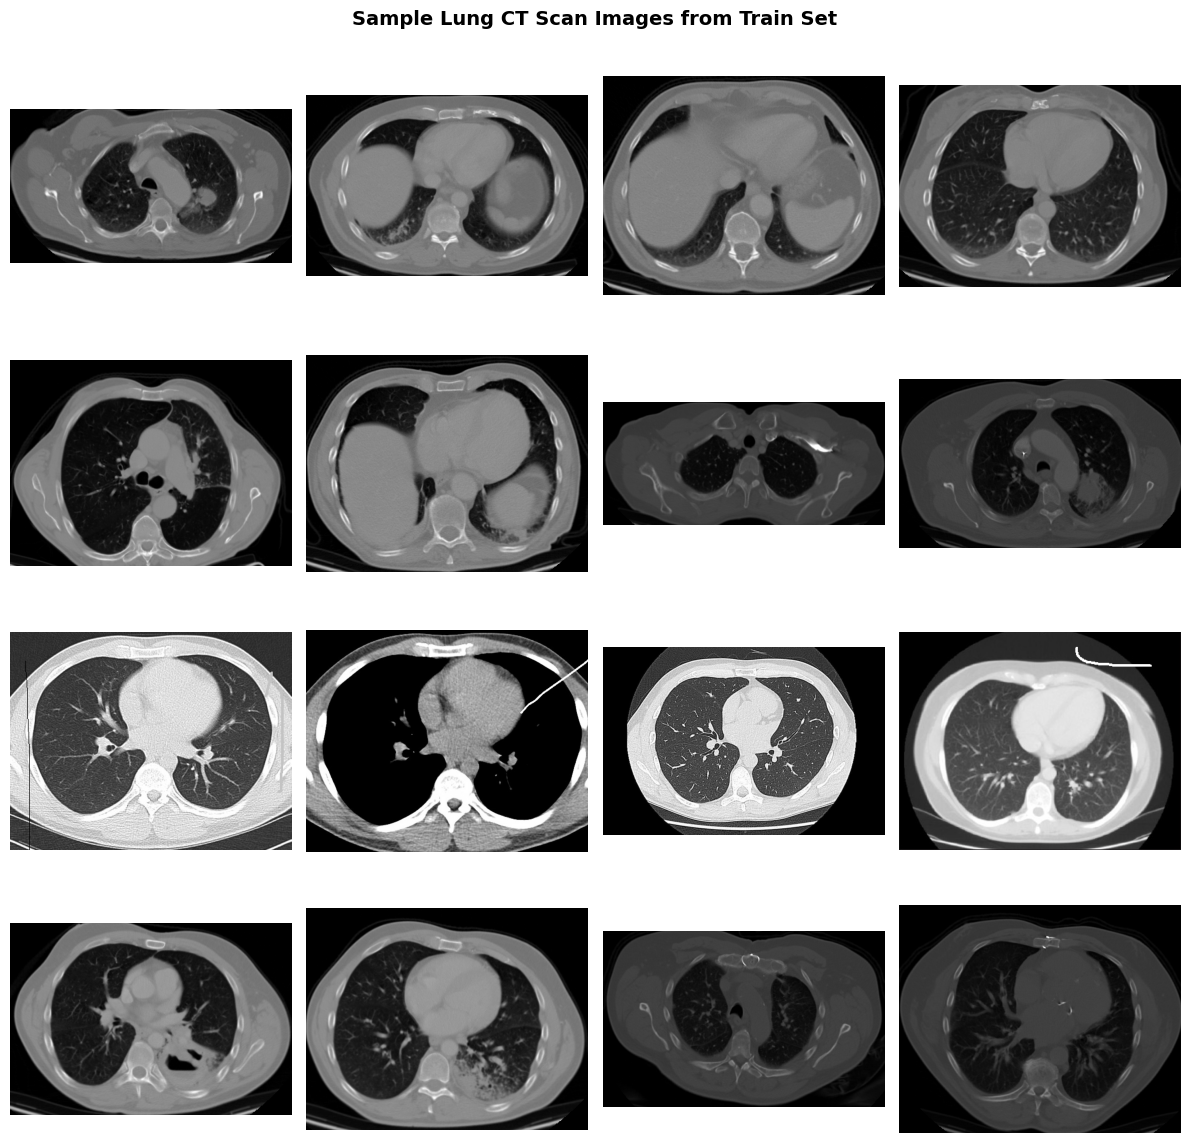

In [13]:
# The original class_names was ['test', 'train', 'valid'] which are splits, not actual image classes.
# Get actual image class names from the 'train' subdirectory.
# This assumes 'train' is representative and exists.
train_split_path = DATA_DIR / 'train'
if train_split_path.is_dir():
    image_class_names = sorted([d.name for d in train_split_path.iterdir() if d.is_dir()])
else:
    # Fallback or error if 'train' split is not found
    image_class_names = []
    print(f"Warning: '{train_split_path}' directory not found to determine image class names.")

# The dataset also has 'test' and 'valid' splits at the same level as 'train'.
# Let's define the overall split names for consistency.
dataset_split_names = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])

print(f"Actual image classes found: {image_class_names}")
print(f"Dataset splits found: {dataset_split_names}")


# Visualize sample images - now adjusted to handle the split-class structure
def plot_sample_images(base_data_dir, actual_class_names, n_samples_per_class=4, sample_from_split='train'):
    """Plot sample images from each actual class within a specified dataset split."""

    if not actual_class_names:
        print("No image classes defined for plotting.")
        return

    sample_split_dir = base_data_dir / sample_from_split
    if not sample_split_dir.is_dir():
        print(f"Warning: Sample split directory '{sample_split_dir}' not found. Cannot plot sample images.")
        return

    n_classes = len(actual_class_names)
    # Adjust n_rows dynamically based on n_samples_per_class to prevent empty plots if n_classes=1
    n_cols = n_samples_per_class if n_classes == 1 else min(n_samples_per_class, 4) # Limit columns for better display
    n_rows = n_classes if n_classes > 0 else 1
    if n_cols == 0: n_cols = 1 # Avoid division by zero if n_samples_per_class is 0

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))

    # Flatten axes for easier iteration, handling cases where axes might be 1D or 2D
    if n_rows * n_cols == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    ax_idx = 0
    for i, cls in enumerate(actual_class_names):
        cls_dir = sample_split_dir / cls # e.g., data/Data/train/adenocarcinoma
        if not cls_dir.is_dir():
            print(f"Warning: Class directory {cls_dir} not found in {sample_from_split} split. Skipping for this class.")
            continue

        images = [f for f in cls_dir.glob('*') if f.is_file()][:n_samples_per_class]

        for j, img_path in enumerate(images):
            if ax_idx < len(axes): # Ensure we don't go out of bounds if fewer samples than expected
                ax = axes[ax_idx]
                try:
                    img = plt.imread(str(img_path))
                    ax.imshow(img, cmap='gray' if len(img.shape) == 2 else None)
                    ax.axis('off')
                    if j == 0: # Only set label for the first image of each class
                        ax.set_ylabel(cls, fontsize=12, rotation=0, ha='right')
                except Exception as e:
                    print(f"Error reading image {img_path}: {e}")
                    ax.axis('off')
                    if j == 0:
                        ax.set_ylabel(f"{cls}\n(Error)", fontsize=10, rotation=0, ha='right', color='red')
                ax_idx += 1

    # Hide any remaining empty subplots
    for k in range(ax_idx, len(axes)):
        axes[k].axis('off')

    plt.suptitle(f'Sample Lung CT Scan Images from {sample_from_split.capitalize()} Set', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Call to visualize sample images from the 'train' split
plot_sample_images(DATA_DIR, image_class_names, n_samples_per_class=4, sample_from_split='train')

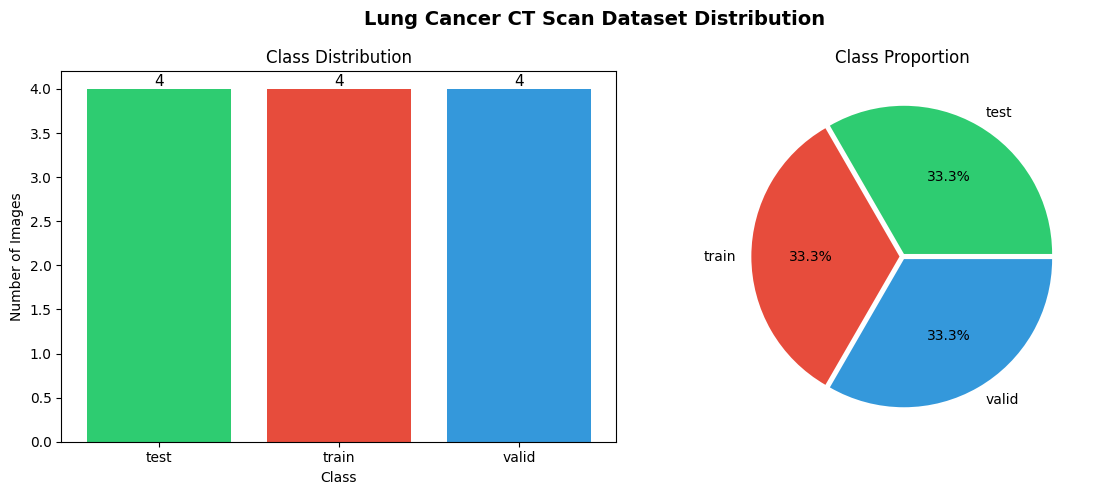

In [14]:
# Plot class distribution
def plot_class_distribution(data_dir, class_names):
    """Plot class distribution"""
    counts = []
    for cls in class_names:
        cls_dir = data_dir / cls
        count = len(list(cls_dir.glob('*')))
        counts.append(count)

    colors = ['#2ecc71', '#e74c3c', '#3498db']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Bar chart
    bars = ax1.bar(class_names, counts, color=colors[:len(class_names)])
    ax1.set_xlabel('Class')
    ax1.set_ylabel('Number of Images')
    ax1.set_title('Class Distribution')
    for bar, count in zip(bars, counts):
        ax1.annotate(f'{count}', xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=11)

    # Pie chart
    ax2.pie(counts, labels=class_names, autopct='%1.1f%%', colors=colors[:len(class_names)],
            explode=[0.02]*len(class_names))
    ax2.set_title('Class Proportion')

    plt.suptitle('Lung Cancer CT Scan Dataset Distribution', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_class_distribution(DATA_DIR, class_names)

## 4. Data Preprocessing and Splitting

In [15]:
# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.0001
VALIDATION_SPLIT = 0.2

# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=VALIDATION_SPLIT
)

# Create training generator
train_generator = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Create validation generator
val_generator = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(f"\n✅ Data generators created!")
print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Class indices: {train_generator.class_indices}")
print(f"Number of classes: {train_generator.num_classes}")

Found 801 images belonging to 3 classes.
Found 199 images belonging to 3 classes.

✅ Data generators created!
Training samples: 801
Validation samples: 199
Class indices: {'test': 0, 'train': 1, 'valid': 2}
Number of classes: 3


## 5. Model Architecture - Transfer Learning with ResNet50

In [16]:
def build_model(num_classes, input_shape=(224, 224, 3)):
    """Build lung cancer detection model using ResNet50 transfer learning"""

    # Load pre-trained ResNet50 model
    base_model = ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    # Freeze base model layers
    for layer in base_model.layers:
        layer.trainable = False

    # Build custom top layers
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

# Build and compile model
NUM_CLASSES = train_generator.num_classes
model = build_model(NUM_CLASSES)

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,804,483 (94.62 MB)

 Trainable params: 1,215,235 (4.64 MB)

 Non-trainable params: 23,589,248 (89.99 MB)

## 6. Model Training

In [17]:
# Define callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=4,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        'lung_cancer_model_best.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Calculate class weights
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weight_dict = dict(enumerate(class_weights))
print(f"Class weights: {class_weight_dict}")

Class weights: {0: np.float64(1.0595238095238095), 1: np.float64(0.5437881873727087), 2: np.float64(4.603448275862069)}


In [18]:
# Train the model
print("\n🚀 Starting training...\n")

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=val_generator.samples // BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

print("\n✅ Training completed!")


🚀 Starting training...

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.4414 - auc: 0.5540 - loss: 1.6070
Epoch 1: val_accuracy improved from -inf to 0.63542, saving model to lung_cancer_model_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 40s 916ms/step - accuracy: 0.4417 - auc: 0.5536 - loss: 1.6098 - val_accuracy: 0.6354 - val_auc: 0.6854 - val_loss: 0.9724 - learning_rate: 1.0000e-04
Epoch 2/30
 1/25 ━━━━━━━━━━━━━━━━━━━━ 2:19 6s/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.5974
Epoch 2: val_accuracy did not improve from 0.63542
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.5974 - val_accuracy: 0.6354 - val_auc: 0.6562 - val_loss: 0.9745 - learning_rate: 1.0000e-04
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.4401 - auc: 0.5547 - loss: 1.5657
Epoch 3: val_accuracy improved from 0.63542 to 0.75521, saving model to lung_cancer_model_best.keras
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 677ms/step - accuracy: 0

## 7. Training History Visualization

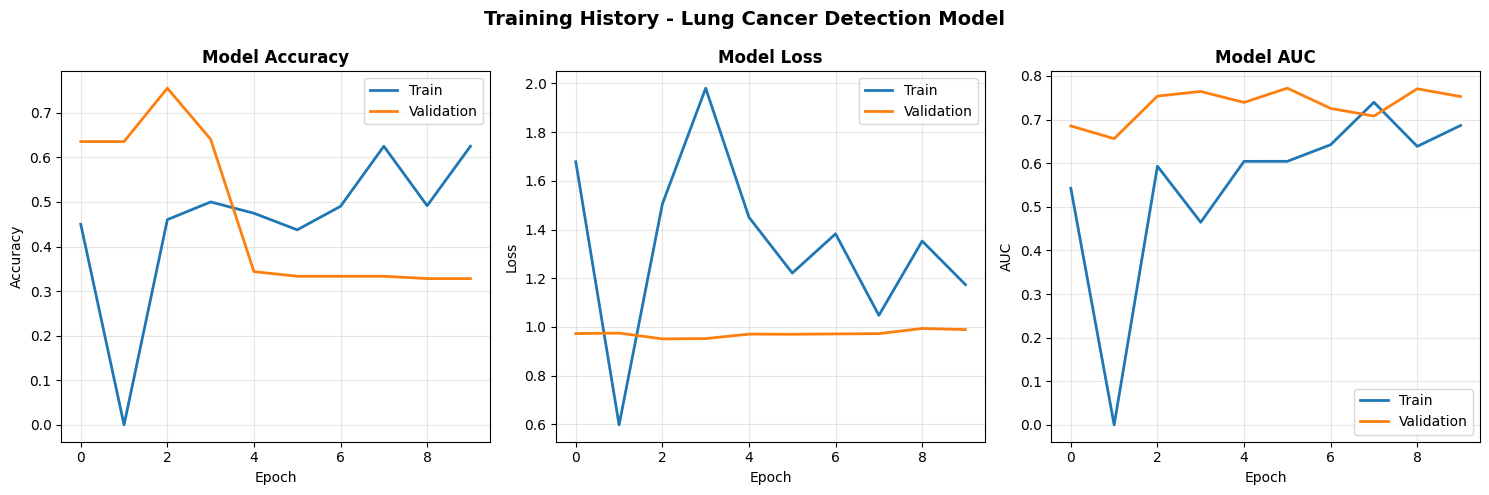

In [19]:
def plot_training_history(history):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title('Model Accuracy', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title('Model Loss', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # AUC
    axes[2].plot(history.history['auc'], label='Train', linewidth=2)
    axes[2].plot(history.history['val_auc'], label='Validation', linewidth=2)
    axes[2].set_title('Model AUC', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('AUC')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.suptitle('Training History - Lung Cancer Detection Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('lung_cancer_training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_training_history(history)

## 8. Model Evaluation

In [20]:
# Load best model
model = keras.models.load_model('lung_cancer_model_best.keras')

# Get class names in correct order
class_indices = train_generator.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
class_names_ordered = [idx_to_class[i] for i in range(len(idx_to_class))]
print(f"Class order: {class_names_ordered}")

# Evaluate on validation set
print("\n📊 Evaluating model on validation set...\n")
val_generator.reset()
val_results = model.evaluate(val_generator, verbose=1)

print("\n" + "="*50)
print("VALIDATION SET RESULTS")
print("="*50)
for name, value in zip(model.metrics_names, val_results):
    print(f"{name.title()}: {value:.4f}")

Class order: ['test', 'train', 'valid']

📊 Evaluating model on validation set...

7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 967ms/step - accuracy: 0.6326 - auc: 0.5022 - loss: 0.9458

VALIDATION SET RESULTS
Loss: 0.9716
Compile_Metrics: 0.6482


In [21]:
# Get predictions
val_generator.reset()
y_pred_prob = model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = val_generator.classes

# Classification Report
print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_true, y_pred, target_names=class_names_ordered))

7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        test       0.55      0.78      0.64        63
       train       0.77      0.70      0.73       122
       valid       0.00      0.00      0.00        14

    accuracy                           0.67       199
   macro avg       0.44      0.49      0.46       199
weighted avg       0.65      0.67      0.65       199



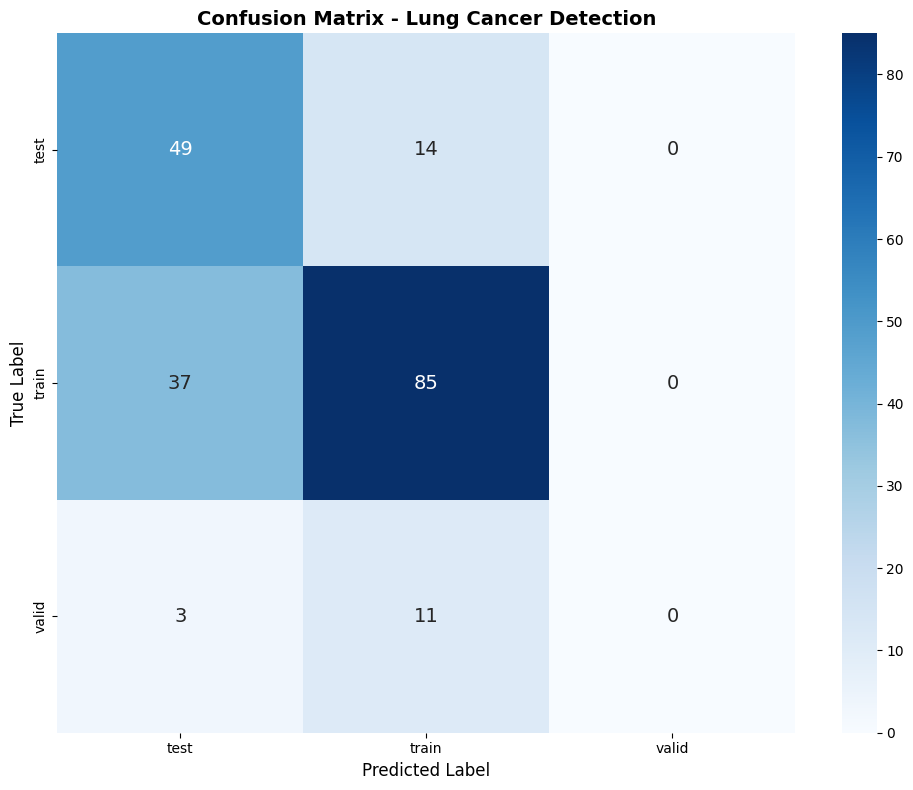


Per-class accuracy:
  test: 0.7778 (49/63)
  train: 0.6967 (85/122)
  valid: 0.0000 (0/14)


In [22]:
# Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, classes):
    """Plot confusion matrix for multi-class"""
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes,
                annot_kws={'size': 14})
    plt.title('Confusion Matrix - Lung Cancer Detection', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.tight_layout()
    plt.savefig('lung_cancer_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print per-class accuracy
    print("\nPer-class accuracy:")
    for i, cls in enumerate(classes):
        cls_total = np.sum(y_true == i)
        cls_correct = cm[i, i]
        accuracy = cls_correct / cls_total if cls_total > 0 else 0
        print(f"  {cls}: {accuracy:.4f} ({cls_correct}/{cls_total})")

plot_confusion_matrix(y_true, y_pred, class_names_ordered)

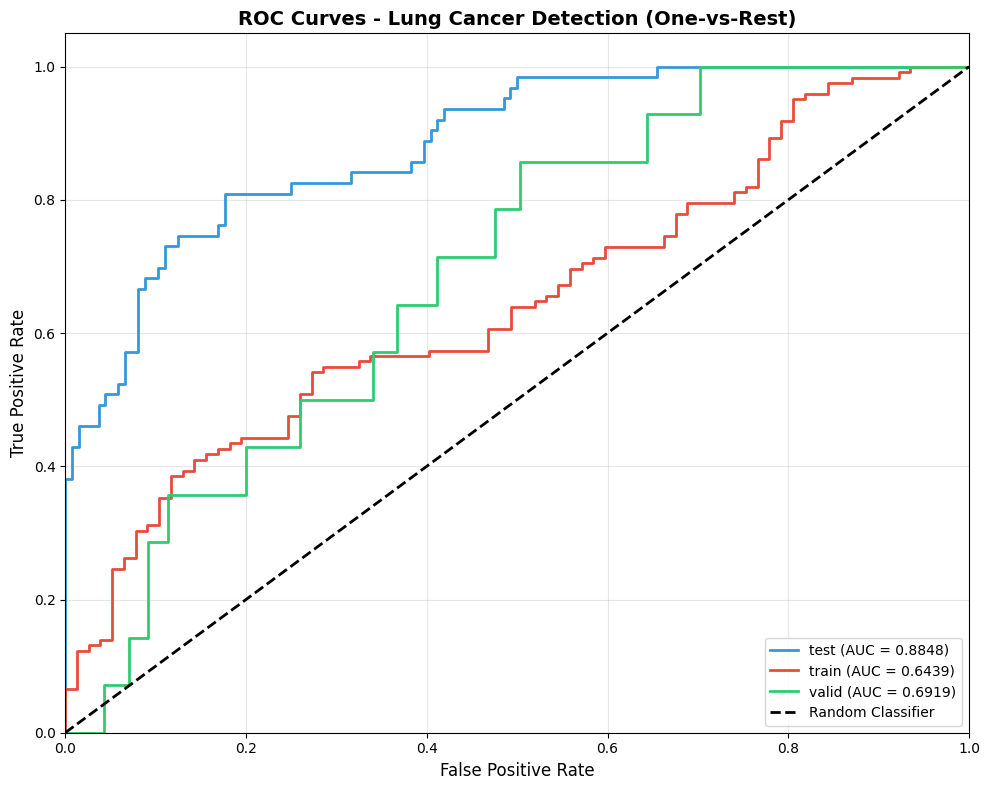

In [23]:
# ROC Curve for Multi-class
def plot_multiclass_roc_curve(y_true, y_pred_prob, classes):
    """Plot ROC curves for each class"""
    # Binarize the labels
    y_true_bin = label_binarize(y_true, classes=range(len(classes)))

    plt.figure(figsize=(10, 8))
    colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6']

    for i, (cls, color) in enumerate(zip(classes, colors)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2,
                label=f'{cls} (AUC = {roc_auc:.4f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curves - Lung Cancer Detection (One-vs-Rest)', fontsize=14, fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('lung_cancer_roc_curves.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_multiclass_roc_curve(y_true, y_pred_prob, class_names_ordered)

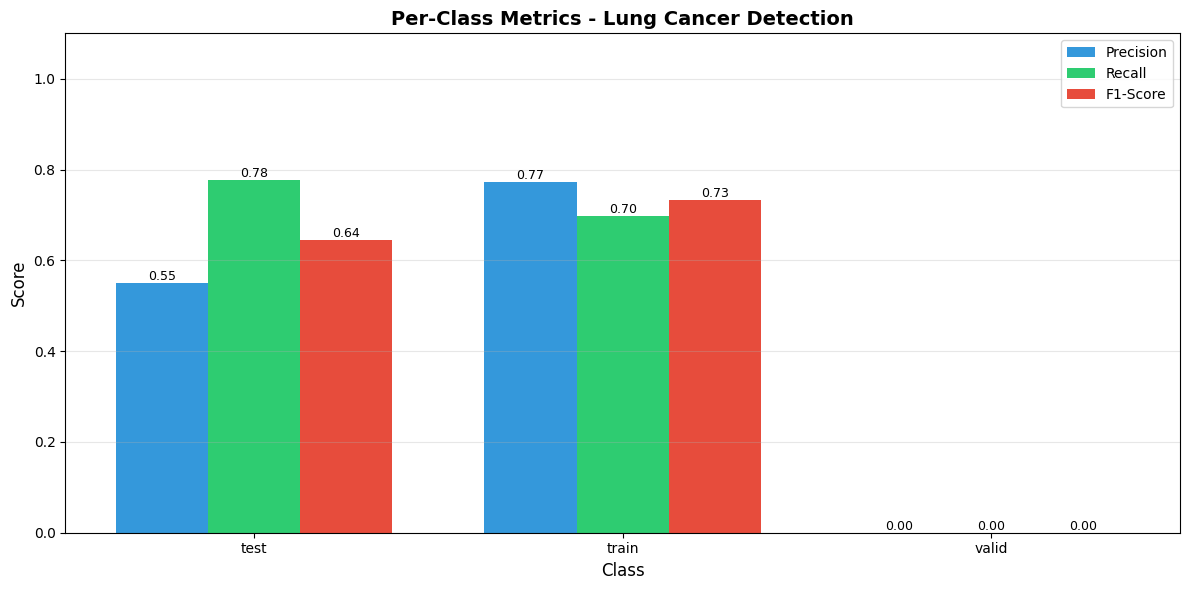

In [24]:
# Per-class metrics visualization
def plot_per_class_metrics(y_true, y_pred, classes):
    """Plot per-class precision, recall, f1-score"""
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)
    f1 = f1_score(y_true, y_pred, average=None)

    x = np.arange(len(classes))
    width = 0.25

    fig, ax = plt.subplots(figsize=(12, 6))

    bars1 = ax.bar(x - width, precision, width, label='Precision', color='#3498db')
    bars2 = ax.bar(x, recall, width, label='Recall', color='#2ecc71')
    bars3 = ax.bar(x + width, f1, width, label='F1-Score', color='#e74c3c')

    ax.set_xlabel('Class', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title('Per-Class Metrics - Lung Cancer Detection', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.legend()
    ax.set_ylim([0, 1.1])
    ax.grid(True, alpha=0.3, axis='y')

    # Add value labels
    for bars in [bars1, bars2, bars3]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height:.2f}',
                       xy=(bar.get_x() + bar.get_width()/2, height),
                       ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.savefig('lung_cancer_per_class_metrics.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_per_class_metrics(y_true, y_pred, class_names_ordered)

In [25]:
# Comprehensive metrics summary
def print_metrics_summary(y_true, y_pred, y_pred_prob, classes):
    """Print comprehensive metrics summary"""
    print("\n" + "="*60)
    print("COMPREHENSIVE METRICS SUMMARY - LUNG CANCER DETECTION")
    print("="*60)

    accuracy = accuracy_score(y_true, y_pred)
    precision_macro = precision_score(y_true, y_pred, average='macro')
    precision_weighted = precision_score(y_true, y_pred, average='weighted')
    recall_macro = recall_score(y_true, y_pred, average='macro')
    recall_weighted = recall_score(y_true, y_pred, average='weighted')
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')

    print(f"\nOverall Metrics:")
    print(f"{'Accuracy':<25s}: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"{'Precision (Macro)':<25s}: {precision_macro:.4f}")
    print(f"{'Precision (Weighted)':<25s}: {precision_weighted:.4f}")
    print(f"{'Recall (Macro)':<25s}: {recall_macro:.4f}")
    print(f"{'Recall (Weighted)':<25s}: {recall_weighted:.4f}")
    print(f"{'F1-Score (Macro)':<25s}: {f1_macro:.4f}")
    print(f"{'F1-Score (Weighted)':<25s}: {f1_weighted:.4f}")

    # Per-class AUC
    print(f"\nPer-Class AUC:")
    y_true_bin = label_binarize(y_true, classes=range(len(classes)))
    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
        roc_auc = auc(fpr, tpr)
        print(f"  {cls:<20s}: {roc_auc:.4f}")

    print("="*60)

print_metrics_summary(y_true, y_pred, y_pred_prob, class_names_ordered)


COMPREHENSIVE METRICS SUMMARY - LUNG CANCER DETECTION

Overall Metrics:
Accuracy                 : 0.6734 (67.34%)
Precision (Macro)        : 0.4411
Precision (Weighted)     : 0.6480
Recall (Macro)           : 0.4915
Recall (Weighted)        : 0.6734
F1-Score (Macro)         : 0.4592
F1-Score (Weighted)      : 0.6533

Per-Class AUC:
  test                : 0.8848
  train               : 0.6439
  valid               : 0.6919


## 9. Save Model

In [26]:
# Save final model
model.save('lung_cancer_model.keras')
print("✅ Model saved as 'lung_cancer_model.keras'")

# Save class mapping
import json
with open('lung_cancer_class_mapping.json', 'w') as f:
    json.dump(class_indices, f)
print("✅ Class mapping saved!")

# Download files
from google.colab import files
files.download('lung_cancer_model.keras')
files.download('lung_cancer_class_mapping.json')
files.download('lung_cancer_training_history.png')
files.download('lung_cancer_confusion_matrix.png')
files.download('lung_cancer_roc_curves.png')
files.download('lung_cancer_per_class_metrics.png')

✅ Model saved as 'lung_cancer_model.keras'
✅ Class mapping saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Sample Predictions Visualization

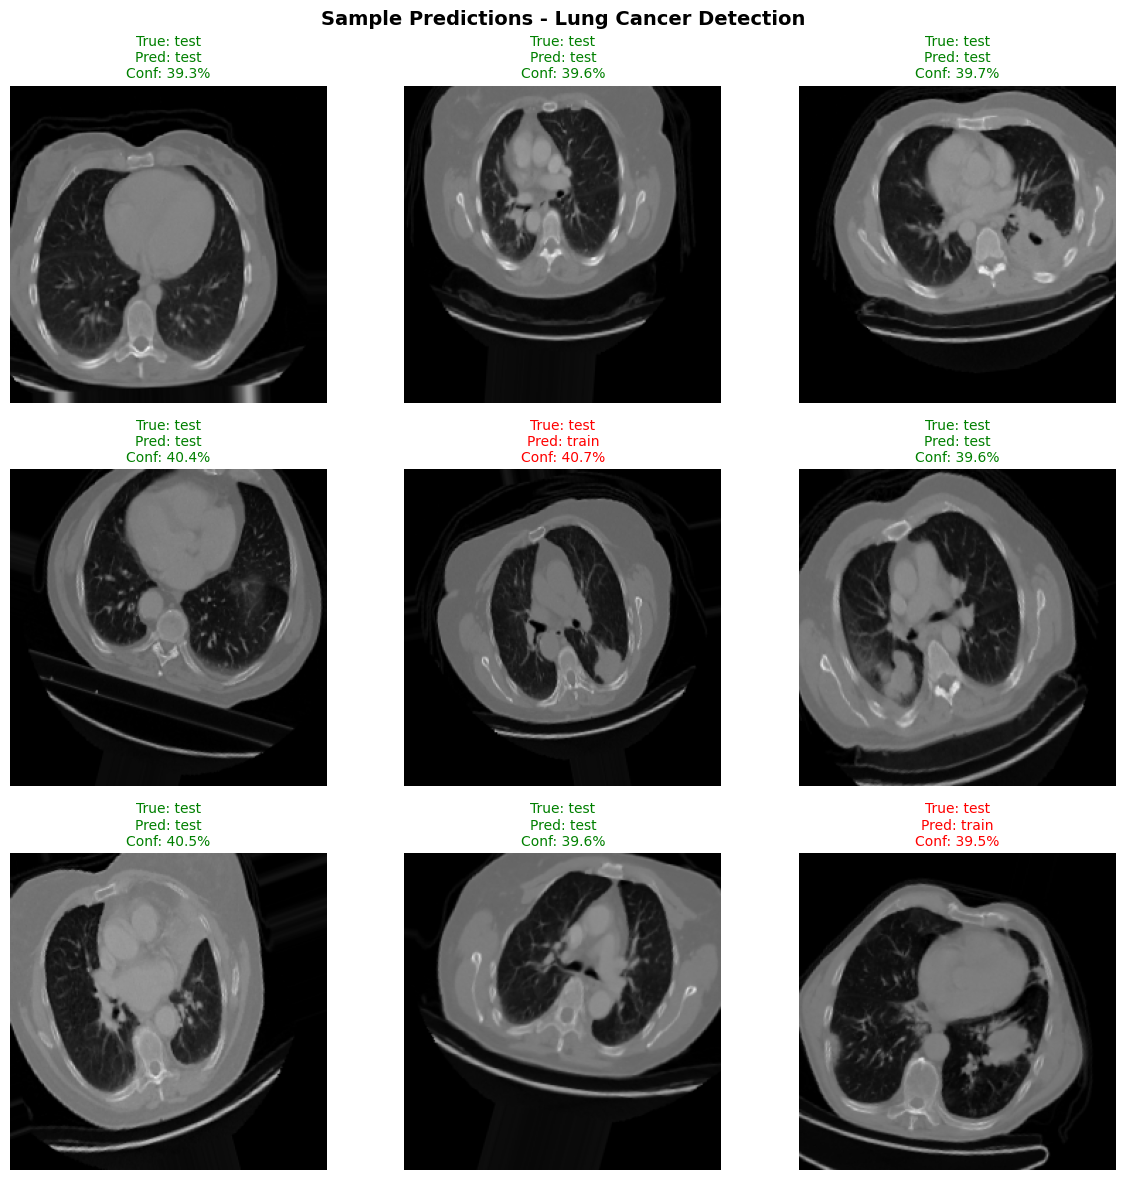

In [27]:
def visualize_predictions(model, generator, class_names, n_samples=9):
    """Visualize sample predictions"""
    generator.reset()
    batch = next(generator)
    images, labels = batch

    predictions = model.predict(images[:n_samples], verbose=0)

    n_cols = 3
    n_rows = (n_samples + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4*n_rows))
    axes = axes.flatten()

    for i in range(n_samples):
        ax = axes[i]
        ax.imshow(images[i])

        pred_class = np.argmax(predictions[i])
        true_class = np.argmax(labels[i])
        confidence = predictions[i][pred_class]

        color = 'green' if pred_class == true_class else 'red'

        ax.set_title(f'True: {class_names[true_class]}\n'
                    f'Pred: {class_names[pred_class]}\n'
                    f'Conf: {confidence*100:.1f}%',
                    color=color, fontsize=10)
        ax.axis('off')

    # Hide empty subplots
    for i in range(n_samples, len(axes)):
        axes[i].axis('off')

    plt.suptitle('Sample Predictions - Lung Cancer Detection', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('lung_cancer_sample_predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

visualize_predictions(model, val_generator, class_names_ordered)

## Summary

This notebook trained a lung cancer detection model using:
- **Dataset**: Kaggle Chest CT Scan Images dataset
- **Architecture**: ResNet50 with transfer learning
- **Input**: 224x224 RGB images
- **Output**: Multi-class classification (Benign/Malignant/Normal)

The model has been saved as `lung_cancer_model.keras` and can be deployed in the HealthMate ML service.